In [20]:
import pandas as pd
import numpy as np
import umap
import glob
import os
import sys
import joblib
from pathlib import Path
import pickle
from scipy.io import readsav
import multiprocess as mp
import datetime

sys.path.insert(0, "cellular_cycle") # add path to the model
from cell_cycle_death_model import model
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap

from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from scipy.signal import find_peaks

# should examine these functions to determine which are best to use (overlapping functionality)
from model_fxns import minmax_scale, stack_sliding_window, calc_minmax, load_sim_output, load_norm_data


In [2]:
SAVE_DIR = Path(Path.home(),'ECM_mod_output/UMAP/ODE_embeddings')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RED_DIR = Path(Path.home(),'ECM_mod_output/UMAP') # directory for UMAP reducer object

OVERWRITE = False
SET_JPARAM = False
PSO_NUM = 2

sys_type = sys.platform

In [3]:
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05



In [4]:
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240730'
    r_dbpath = 'https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '20240820'
    r_dbpath = 'https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

if SET_JPARAM:
    r_name = f'reducerPSO_{PSO_NUM}_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'
else:
    r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [5]:
print(f'Reducer filename: {r_name}')

Reducer filename: reducer_win_0.1_0.1_4_0.5.sav


In [6]:
r_path = Path(SAVE_DIR,'UMAP',r_name)

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=C:\Users\olesk\ECM_mod_output\UMAP\ODE_embeddings\UMAP\reducer_win_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1


In [7]:
r_path = Path(RED_DIR,r_name)

if not r_path.exists():
    %env R_DBPATH = {r_dbpath}
    print(f'Reducer file not found, downloading from Dropbox: {r_dbpath}')
    !wget -O $R_PATH $R_DBPATH
print(f'Loading reducer from {r_path}')
reducer = joblib.load(r_path)

Loading reducer from C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav


In [25]:
FILE_LOC = Path(Path.home(),'ECM_mod_output/ODE_output')
if SET_JPARAM:
    filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC) if  f'psoparam_{PSO_NUM}' in f]
else:
    filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC) if  'range' in f]    
    
all_odes = sorted(filenames)

In [26]:
all_odes[:5]

[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_output/DMSO_range_000.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_output/DMSO_range_001.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_output/DMSO_range_002.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_output/DMSO_range_003.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_output/DMSO_range_004.csv')]

In [27]:
assert len(all_odes) == 2000

In [28]:
exp_stiff_vals = ['000','049','099']
SAVE_DIR = Path(Path.home(),'ECM_mod_output')

In [29]:
if SET_JPARAM:
    stoch_filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and f'pso_{PSO_NUM}' in f and not 'orig' in f]
    stoch_filenames.sort()
else:
    stoch_filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_stiff_' in f and 'orig' in f]
    stoch_filenames.sort()


stoch_filenames.sort()
stoch_filenames

[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_099_orig.csv')]

In [30]:
stoch_filenames_umap = [f for f in stoch_filenames if any([x in str(f) for x in exp_stiff_vals])]
stoch_filenames_umap

[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_099_orig.csv')]

In [31]:
ode_filenames = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames]
ode_filenames

[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_099_orig.csv')]

In [32]:
ode_filenames_umap = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames_umap]
ode_filenames_umap

[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_099_orig.csv')]

In [33]:
max_prots, min_prots = calc_minmax(stoch_filenames_umap + ode_filenames_umap)

In [12]:
PARAM = pd.read_csv(Path('model_data/parameters.csv'))  # parameter file to use
INIT_CONCS = pd.read_csv(Path('model_data/initial_concentrations.csv'))  # initial concentrations for simulations

TREATMENT = 'DMSO'  # set AKT, ERK, and FAK by setting 'ERL' or 'DMSO'
 
CYCDI_CONC = 0
POINTS = 10  # number to divide each condition into, sets the number of points to divide cell cycle

# number of processes to reserve; set to either 10% or 1, whichever is greater
if round(mp.cpu_count()*0.1,0) < 1:
    RES_PROC = 1
else:
    RES_PROC = round(mp.cpu_count()*0.1,0)

PROCESSES = int(mp.cpu_count() - RES_PROC)  # number of pool processes to run at once
SAVEFILES = True  # save files for lyapunov values and mean IMT values
OVERWRITE = False  # Overwrite existing files
VERBOSE = True
SET_JPARAM = False
PARAM_NUM = 2

integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(), 'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [15]:
CURDATE = datetime.datetime.now().strftime('%Y%m%d')

t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1

# Importing the parameters:

for key in PARAM.keys():
    try:
        if model.parameters[key].value != PARAM[key][0]:
            model.parameters[key].value = PARAM[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [16]:
if SET_JPARAM:
    with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
        frac_prolif_parameters_pso = pickle.load(f)

    frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 55 kPa erlotinib')]
    pso_sort_pops = frac_prolif_parameters_pso.sort_values(by=[('cost', 'custom cost populations')])
    new_params = pso_sort_pops['model parameters']
    # Importing the parameters:
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[PARAM_NUM]:
                model.parameters[key].value = new_params[key].iloc[PARAM_NUM]
        except:
            print(key)
    model.parameters['omega'].value = 200

In [17]:
for key in INIT_CONCS.keys():
    try:
        model.parameters[key].value = INIT_CONCS[key][0] / model.parameters['omega'].value
    except:
        print(key)

model.parameters['CycDi_0'].value = CYCDI_CONC

if TREATMENT == 'ERL':
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.3,51))
    tmp = list(np.linspace(0.3,0.6,51))
    AKTs.extend(tmp[1:])
    tmp = [0.6]*50
    AKTs.extend(tmp)
    
    ERKs = [0.2]*151
    
elif TREATMENT == 'DMSO':
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.6,51))
    tmp = list(np.linspace(0.6,1,51))
    AKTs.extend(tmp[1:])
    tmp = [1]*50
    AKTs.extend(tmp)
    
    ERKs = [1]*151
else:
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.3,51))
    tmp = list(np.linspace(0.3,0.6,51))
    AKTs.extend(tmp[1:])
    tmp = [0.6]*50
    AKTs.extend(tmp)
    
    ERKs = [0.1]*151

conds = [(AKT, ERK, FAK) for AKT, ERK, FAK, in zip(AKTs, ERKs, FAKs)]

In [53]:
AKT = 1
ERK = 1
FAK = 1
model.parameters['AKT'].value = AKT
model.parameters['ERK'].value = ERK
model.parameters['FAK'].value = FAK
points = 10
verbose = True
# ep = 0.001 * 200
ep = 0.001
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
dt = t[1]-t[0]
all_logz = dict.fromkeys(list(range(1, points + 1)))

In [54]:
kk = 0
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                            integrator_options=integrator_options).run()
y_out = sim_ode.observables

peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence=0.6, distance=10)
# new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
peaks_half2 = peaks_cdc[peaks_cdc > len(y_out) / 2]
names = y_out.dtype.names  

In [58]:
if len(peaks_half2) > 3:
    IMTs = [t[y] - t[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
    meanIMT = sum(IMTs) / len(IMTs)
    stdIMT = np.std(IMTs)
    tmp_range = y_out[peaks_half[-4]:peaks_half[-2]]
    ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
    t_slice = t[peaks_half[-4]:peaks_half[-2]]
    tmp_loc = (round(len(tmp_range) / (points)) * (kk))
else:
    meanIMT = 0
    tmp_range = y_out[575000:600000]
    ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
    tmp_loc = (round(len(tmp_range) / (points)) * (kk))
    t_slice = t[575000:600000]
if verbose:
    print(meanIMT)

22.124714285714287


In [59]:
def finite_diff_loop(arr, t):
    """
    Finite difference for one-period template (shape: (M,d)).
    Handles non-uniform time spacing and enforces periodic wrap.

    Parameters
    ----------
    arr : ndarray, shape (M,d)
        One-period trajectory samples.
    t : ndarray, shape (M,)
        Corresponding times or phases (need not be uniform).

    Returns
    -------
    darr : ndarray, shape (M,d)
        Estimated derivatives at each point.
    """
    arr = np.asarray(arr, dtype=float)
    t = np.asarray(t, dtype=float)
    M, d = arr.shape
    darr = np.zeros_like(arr)

    # interior points: np.gradient handles non-uniform t
    for j in range(d):
        darr[:, j] = np.gradient(arr[:, j], t)

    # periodic wrap: replace first/last rows with central diff across boundary
    dt0 = (t[1] - t[0]) + (t[-1] - t[-2])  # average step near edges
    darr[0]  = (arr[1] - arr[-1]) / (t[1] - t[-1] + (t[-1]-t[0]))
    darr[-1] = (arr[0] - arr[-2]) / (t[0] - t[-2] + (t[-1]-t[0]))

    return darr

def transverse_distance_series(x_traj, ref_cycle, ref_dcycle):
    # dense grid of phases
    M = ref_cycle.shape[0]
    rs = []
    for x in x_traj:
        # phase alignment: nearest point on reference cycle
        j = np.argmin(np.linalg.norm(ref_cycle - x, axis=1))
        v = ref_dcycle[j]
        vhat = v / (np.linalg.norm(v) + 1e-12)
        d = x - ref_cycle[j]
        d_perp = d - np.dot(d, vhat) * vhat
        rs.append(np.linalg.norm(d_perp))
    return np.array(rs)

def perturb_orthogonal_nonneg(
    x19, ref_cycle, ref_dcycle,
    magnitude=1e-3,     # preferred absolute perturbation size
    safety=0.9,         # back off a bit from the hard bound
    rng=None
):
    """
    Add a perturbation to x19 in a direction orthogonal to the cycle tangent,
    with preferred absolute size 'magnitude', while ensuring all components
    remain nonnegative.

    Parameters
    ----------
    x19 : (d,) array
        Current state (must be nonnegative).
    ref_cycle : (M,d) array
        One-period template trajectory.
    ref_dcycle : (M,d) array
        Tangent vectors along ref_cycle.
    magnitude : float
        Preferred absolute size of perturbation (Euclidean norm).
    safety : float
        Shrink the maximum step slightly to avoid hitting 0 exactly.
    rng : np.random.Generator, optional
        Random generator for fallback if needed.

    Returns
    -------
    x_new : (d,) array
        Perturbed, nonnegative state.
    alpha  : float
        Actual step size used (≤ magnitude).
    """
    x = np.asarray(x19, float).ravel()

    # nearest point on template (phase alignment)
    j = int(np.argmin(np.linalg.norm(ref_cycle - x, axis=1)))
    v = ref_dcycle[j]
    vhat = v / (np.linalg.norm(v) + 1e-12)

    # build a transverse direction
    u = x - ref_cycle[j]
    u = u - np.dot(u, vhat) * vhat
    if np.linalg.norm(u) < 1e-12:
        if rng is None:
            rng = np.random.default_rng()
        w = rng.normal(size=x.shape)
        u = w - np.dot(w, vhat) * vhat
    uhat = u / (np.linalg.norm(u) + 1e-12)

    # maximum admissible alpha so that x + alpha*uhat >= 0
    neg_dir = uhat < 0
    if np.any(neg_dir):
        alpha_max = np.min(x[neg_dir] / (-uhat[neg_dir] + 1e-18))
    else:
        alpha_max = np.inf

    # choose actual step
    if np.isfinite(alpha_max):
        alpha = min(magnitude, safety * max(alpha_max, 0.0))
    else:
        alpha = magnitude

    # apply perturbation
    x_new = x + alpha * uhat
    x_new[x_new < 0] = 0.0  # clamp tiny negatives
    return x_new, float(alpha)

In [60]:
ref_dcycle = finite_diff_loop(ref_cycle, t_slice)

In [61]:
row = tmp_range[tmp_loc]
names19 = names[:19]
x19 = np.array([row[n] for n in names19], float)

In [62]:
# kick orthogonal to the tangent with preferred magnitude 0.01
x19_pert, alpha_used = perturb_orthogonal_nonneg(
    x19, ref_cycle, ref_dcycle, magnitude=0.01
)

prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
         'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
         'Cdc20_0']
prot_init = {prots[i]: float(x19_pert[i]) for i in range(len(prots))}

# set initial conditions from first simulation
for key in prot_init.keys():
    model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

# t1 = np.arange(0,t_slice[-1]-t_slice[0],dt)
t1 = np.linspace(0, 1000, 1000001)
sim_ode1 = ScipyOdeSimulator(model, t1, verbose=False, integrator_options=integrator_options).run()
y_out1 = sim_ode1.observables
X1 = np.column_stack([y_out1[n] for n in names[:19]])

In [63]:
ref_cycle = ref_cycle[::100, :] 

In [64]:
X1 = X1[::100, :]

In [65]:
t = np.arange(0,0.1*len(ref_cycle),0.1)

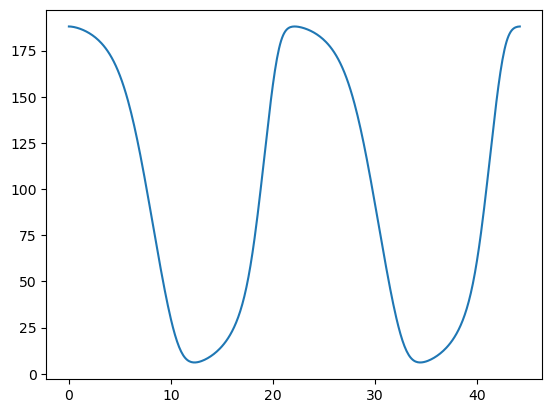

In [66]:
plt.plot(t, ref_cycle[:,18])

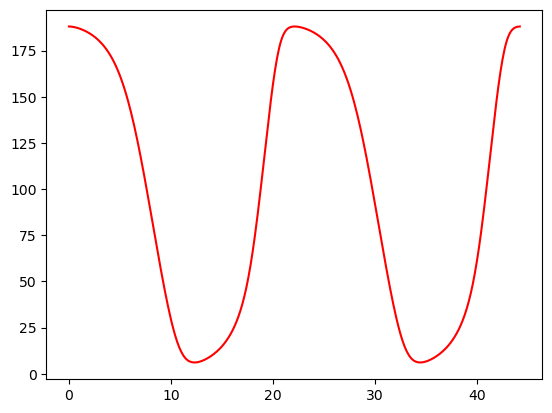

In [75]:
plt.plot(t, X1[:len(t),18], c='r')

In [70]:
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

In [71]:
win_len = int(window/dt)

In [72]:
columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]

prot_tmp = pd.DataFrame(ref_cycle, columns=columns)
prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])

range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))

for ii in range(18):
    prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

prot_re_tmp = np.empty((len(range_ind),win_len*18))
time_re_tmp = np.empty((len(range_ind),win_len))
time_at_tmp = np.empty((len(range_ind),1))

ii=0
for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
    tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
    #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
    tmp=tmp.to_numpy()
    tmp=np.reshape(np.transpose(tmp),win_len*18)
    #tmp_at = time_tmp2['time'].iloc[n]

    prot_re_tmp[ii,:] = np.array([tmp])
    #time_re_tmp[ii,:] = np.array([tmp_t])
    #time_at_tmp[ii,:] = np.array([[tmp_at]])
    ii+=1

In [73]:
embedding_tmp = reducer.transform(prot_re_tmp)

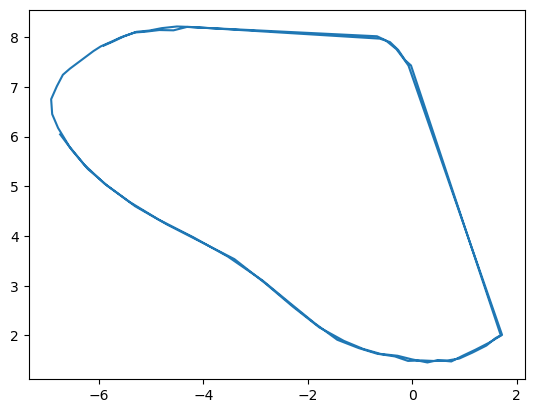

In [74]:
plt.plot(embedding_tmp[:,0], embedding_tmp[:,1])

In [76]:
prot_tmp = pd.DataFrame(X1, columns=columns)
prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])

range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))

for ii in range(18):
    prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

prot_re_tmp = np.empty((len(range_ind),win_len*18))
time_re_tmp = np.empty((len(range_ind),win_len))
time_at_tmp = np.empty((len(range_ind),1))

ii=0
for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
    tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
    #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
    tmp=tmp.to_numpy()
    tmp=np.reshape(np.transpose(tmp),win_len*18)
    #tmp_at = time_tmp2['time'].iloc[n]

    prot_re_tmp[ii,:] = np.array([tmp])
    #time_re_tmp[ii,:] = np.array([tmp_t])
    #time_at_tmp[ii,:] = np.array([[tmp_at]])
    ii+=1

In [77]:
embedding_X1 = reducer.transform(prot_re_tmp)

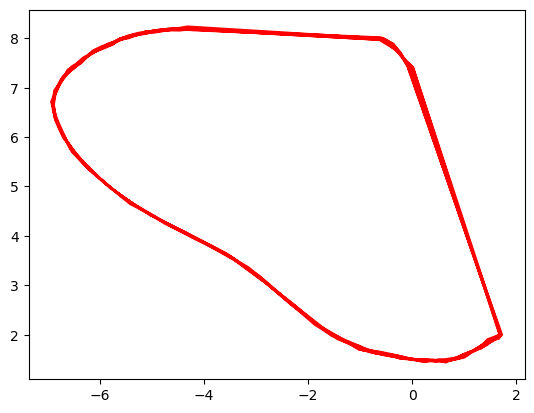

In [79]:
plt.plot(embedding_X1[:len(t),0], embedding_X1[:len(t),1], c='r')

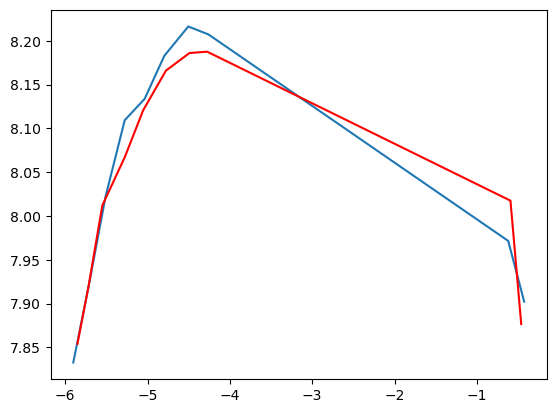

In [85]:
plt.plot(embedding_tmp[:10,0], embedding_tmp[:10,1])
plt.plot(embedding_X1[:10,0], embedding_X1[:10,1], c='r')

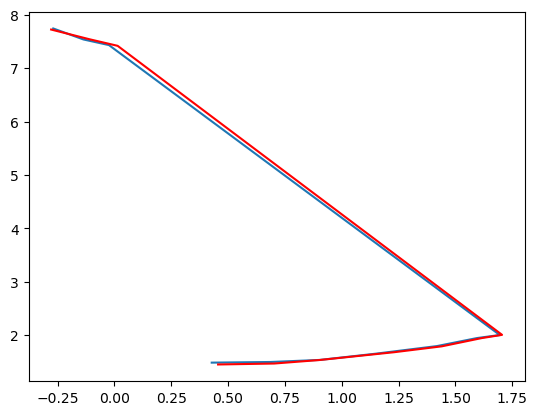

In [86]:
plt.plot(embedding_tmp[10:20,0], embedding_tmp[10:20,1])
plt.plot(embedding_X1[10:20,0], embedding_X1[10:20,1], c='r')